# Agent X Experiments: Baseline Machine Learning & Backtesting Pipeline

This Google Colab-compatible notebook demonstrates a complete, leak-free machine learning workflow for predicting stock price direction and evaluating a quantitative trading strategy with realistic transaction costs.

### Key Highlights:
1. **Data Acquisition**: Free historical stock data via `yfinance` (No paid APIs).
2. **Feature Engineering**: Strictly backward-looking technical indicators (SMA ratios, RSI, Volatility, Lags).
3. **Data Leakage Prevention**: Proper lag alignment, forward target shift, and chronological train/test split.
4. **Baseline ML Model**: Random Forest Classifier trained on chronological training data.
5. **Backtesting with Transaction Costs**: Backtest incorporating trading costs/slippage per turnover.
6. **Performance Evaluation**: Returns, Sharpe Ratio, Max Drawdown comparisons vs. Buy & Hold benchmark.
7. **Safety**: Simulation-only; no real trading or external execution APIs.

## Step 1: Environment Setup & Data Acquisition
We install necessary dependencies (`yfinance`, `scikit-learn`, `pandas`, `matplotlib`) and download historical price data for **AAPL**.

In [1]:
# Install dependencies if running in Colab
!pip install -q yfinance pandas numpy scikit-learn matplotlib

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Set seed for reproducibility
np.random.seed(42)

# Download historical daily data for AAPL
TICKER = "AAPL"
START_DATE = "2018-01-01"
END_DATE = "2023-12-31"

print(f"Downloading {TICKER} data from {START_DATE} to {END_DATE}...")
df = yf.download(TICKER, start=START_DATE, end=END_DATE, auto_adjust=True)

# Handle MultiIndex columns if present in newer yfinance versions
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

print(f"Data shape: {df.shape}")
df.head()


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


/home/jules/.pyenv/versions/3.12.13/lib/python3.12/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/jules/.pyenv/versions/3.12.13/lib/python3.12/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/jules/.pyenv/versions/3.12.13/lib/python3.12/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more de

Data shape: (1509, 5)



/home/jules/.pyenv/versions/3.12.13/lib/python3.12/site-packages/yfinance/multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
/home/jules/.pyenv/versions/3.12.13/lib/python3.12/site-packages/yfinance/multi.py:224: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.sort_index(level=0, axis=1, inplace=True)


Price,Close,High,Low,Open,Volume
Date,,,,,
2018-01-02,40.232384,40.241728,39.531715,39.741918,102223600
2018-01-03,40.225368,40.767220,40.162311,40.295436,118071600
2018-01-04,40.412228,40.514993,40.190350,40.297784,89738400
2018-01-05,40.872334,40.958748,40.416900,40.507986,94640000
2018-01-08,40.720509,41.014788,40.622412,40.720509,82271200


## Step 2: Feature Engineering & Data Leakage Prevention

### Avoiding Data Leakage:
- **Predictor Features**: Calculated strictly using information available at or prior to close on day $t$ (e.g. `Close[t] / SMA[t] - 1`, `RSI[t]`, lagged returns `Return[t-1]`).
- **Target Variable**: The return on day $t+1$ (`Next_Log_Return`), discretized into a binary indicator `Target[t] = 1` if `Next_Log_Return > 0` else `0`.
- **No Lookahead**: No future prices or forward-looking rolling windows are used in feature computation.

In [2]:
# Compute log return on day t
df['Log_Return'] = np.log(df['Close'] / df['Close'].shift(1))

# Lagged log returns
df['Lag1'] = df['Log_Return'].shift(1)
df['Lag2'] = df['Log_Return'].shift(2)
df['Lag3'] = df['Log_Return'].shift(3)
df['Lag5'] = df['Log_Return'].shift(5)

# Moving Average Ratios
df['SMA_10_Ratio'] = (df['Close'] / df['Close'].rolling(window=10).mean()) - 1.0
df['SMA_50_Ratio'] = (df['Close'] / df['Close'].rolling(window=50).mean()) - 1.0

# Historical Rolling Volatility
df['Vol_10'] = df['Log_Return'].rolling(window=10).std()
df['Vol_20'] = df['Log_Return'].rolling(window=20).std()

# Relative Strength Index (RSI - 14 period)
delta = df['Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
rs = gain / (loss + 1e-10)
df['RSI_14'] = 100 - (100 / (1 + rs))

# Forward Target Shift: Predict next day return direction (day t+1)
df['Next_Log_Return'] = df['Log_Return'].shift(-1)
df['Target'] = (df['Next_Log_Return'] > 0).astype(int)

# Feature columns definition
FEATURE_COLS = ['Lag1', 'Lag2', 'Lag3', 'Lag5', 'SMA_10_Ratio', 'SMA_50_Ratio', 'Vol_10', 'Vol_20', 'RSI_14']

# Drop NaN rows caused by rolling windows and target shifting
df_clean = df.dropna(subset=FEATURE_COLS + ['Target', 'Next_Log_Return']).copy()

print(f"Clean dataset length: {len(df_clean)}")
print("Feature Summary:")
df_clean[FEATURE_COLS].describe()

Clean dataset length: 1459
Feature Summary:


Price,Lag1,Lag2,Lag3,Lag5,SMA_10_Ratio,SMA_50_Ratio,Vol_10,Vol_20,RSI_14
count,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000
mean,0.001028,0.001034,0.001047,0.001053,0.004895,0.027591,0.017775,0.018166,56.392965
std,0.020090,0.020091,0.020095,0.020098,0.030915,0.078002,0.009735,0.008711,17.216963
min,-0.137708,-0.137708,-0.137708,-0.137708,-0.125394,-0.247456,0.004485,0.006526,3.180581
25%,-0.008459,-0.008459,-0.008459,-0.008499,-0.012406,-0.020269,0.011202,0.012385,43.976155
50%,0.001233,0.001254,0.001266,0.001326,0.007214,0.037810,0.015770,0.016121,57.618782
75%,0.011913,0.011913,0.011918,0.011918,0.024500,0.078029,0.021881,0.021172,69.286257
max,0.113157,0.113157,0.113157,0.113157,0.118199,0.281007,0.080839,0.068108,95.789238


## Step 3: Chronological Train / Test Split

To prevent temporal leakage, standard random k-fold cross-validation is **not** used. Instead, we use a chronological split:
- **Training Set**: Prior to 2022-01-01 (2018 - 2021)
- **Test Set**: 2022-01-01 to 2023-12-31

In [3]:
SPLIT_DATE = '2022-01-01'

train_mask = df_clean.index < SPLIT_DATE
test_mask = df_clean.index >= SPLIT_DATE

X_train = df_clean.loc[train_mask, FEATURE_COLS]
y_train = df_clean.loc[train_mask, 'Target']

X_test = df_clean.loc[test_mask, FEATURE_COLS]
y_test = df_clean.loc[test_mask, 'Target']

print(f"Training set period: {X_train.index.min().date()} to {X_train.index.max().date()} ({len(X_train)} samples)")
print(f"Testing set period:  {X_test.index.min().date()} to {X_test.index.max().date()} ({len(X_test)} samples)")

Training set period: 2018-03-14 to 2021-12-31 (959 samples)
Testing set period:  2022-01-03 to 2023-12-28 (500 samples)


## Step 4: Baseline ML Model Training & Evaluation

We fit a **RandomForestClassifier** on the training set and evaluate its predictive performance on the test set.

=== Model Test Set Performance ===
Accuracy:  0.4880

Classification Report:
              precision    recall  f1-score   support

   Down/Flat       0.41      0.12      0.18       243
          Up       0.50      0.84      0.63       257

    accuracy                           0.49       500
   macro avg       0.45      0.48      0.41       500
weighted avg       0.46      0.49      0.41       500



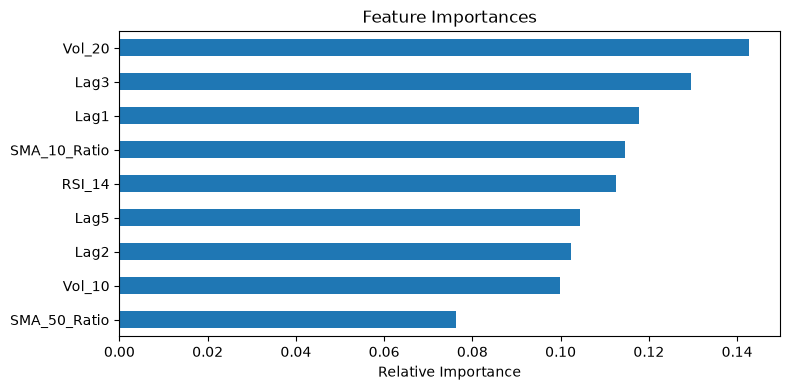

In [4]:
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=10,
    random_state=42
)
model.fit(X_train, y_train)

# Predictions on test set
preds_test = model.predict(X_test)

print("=== Model Test Set Performance ===")
print(f"Accuracy:  {accuracy_score(y_test, preds_test):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, preds_test, target_names=['Down/Flat', 'Up']))

# Feature Importance
importances = pd.Series(model.feature_importances_, index=FEATURE_COLS).sort_values()
plt.figure(figsize=(8, 4))
importances.plot(kind='barh', title='Feature Importances')
plt.xlabel('Relative Importance')
plt.tight_layout()
plt.show()

## Step 5: Backtesting Engine with Transaction Costs

### Trading Rules:
- If Signal = 1 (Up prediction): Hold long position for day $t+1$.
- If Signal = 0 (Down/Flat prediction): Stay in Cash (0 position) for day $t+1$.
- **Transaction Cost Modeling**: A cost penalty (e.g. 10 bps = 0.10% per transaction) is deducted whenever the strategy changes position (0 to 1 or 1 to 0).

In [5]:
TRANSACTION_COST_PCT = 0.0010  # 10 bps (0.10%) per position change

# Prepare backtest DataFrame on test split
backtest_df = df_clean.loc[test_mask].copy()
backtest_df['Signal'] = preds_test

# Track position turnover
backtest_df['Position_Change'] = backtest_df['Signal'].diff().abs().fillna(backtest_df['Signal'])
backtest_df['Transaction_Cost'] = backtest_df['Position_Change'] * TRANSACTION_COST_PCT

# Calculate Strategy Daily Return
backtest_df['Strategy_Return'] = (backtest_df['Signal'] * backtest_df['Next_Log_Return']) - backtest_df['Transaction_Cost']

# Cumulative Log Returns to Wealth Index
backtest_df['Cum_Market'] = np.exp(backtest_df['Next_Log_Return'].cumsum())
backtest_df['Cum_Strategy'] = np.exp(backtest_df['Strategy_Return'].cumsum())

# Performance Metrics Calculation Function
def calculate_performance_metrics(log_returns):
    total_return = np.exp(log_returns.sum()) - 1.0
    ann_return = np.exp(log_returns.mean() * 252) - 1.0
    ann_volatility = log_returns.std() * np.sqrt(252)
    sharpe_ratio = (log_returns.mean() * 252) / (ann_volatility + 1e-10)
    
    cum_ret = np.exp(log_returns.cumsum())
    peak = cum_ret.cummax()
    drawdown = (cum_ret - peak) / peak
    max_drawdown = drawdown.min()
    
    return {
        'Total Return': f"{total_return:.2%}",
        'Annualized Return': f"{ann_return:.2%}",
        'Annualized Volatility': f"{ann_volatility:.2%}",
        'Sharpe Ratio': f"{sharpe_ratio:.2f}",
        'Max Drawdown': f"{max_drawdown:.2%}"
    }

market_metrics = calculate_performance_metrics(backtest_df['Next_Log_Return'])
strategy_metrics = calculate_performance_metrics(backtest_df['Strategy_Return'])

summary_df = pd.DataFrame([market_metrics, strategy_metrics], index=['Buy & Hold (AAPL)', 'ML Strategy (with Costs)'])
print("=== Out-of-Sample Performance Comparison ===")
summary_df

=== Out-of-Sample Performance Comparison ===


,Total Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Max Drawdown
Buy & Hold (AAPL),6.99%,3.46%,29.04%,0.12,-30.02%
ML Strategy (with Costs),-17.18%,-9.07%,25.83%,-0.37,-36.62%


## Step 6: Strategy Visualization

Plotting equity curves for Buy & Hold vs ML Strategy.

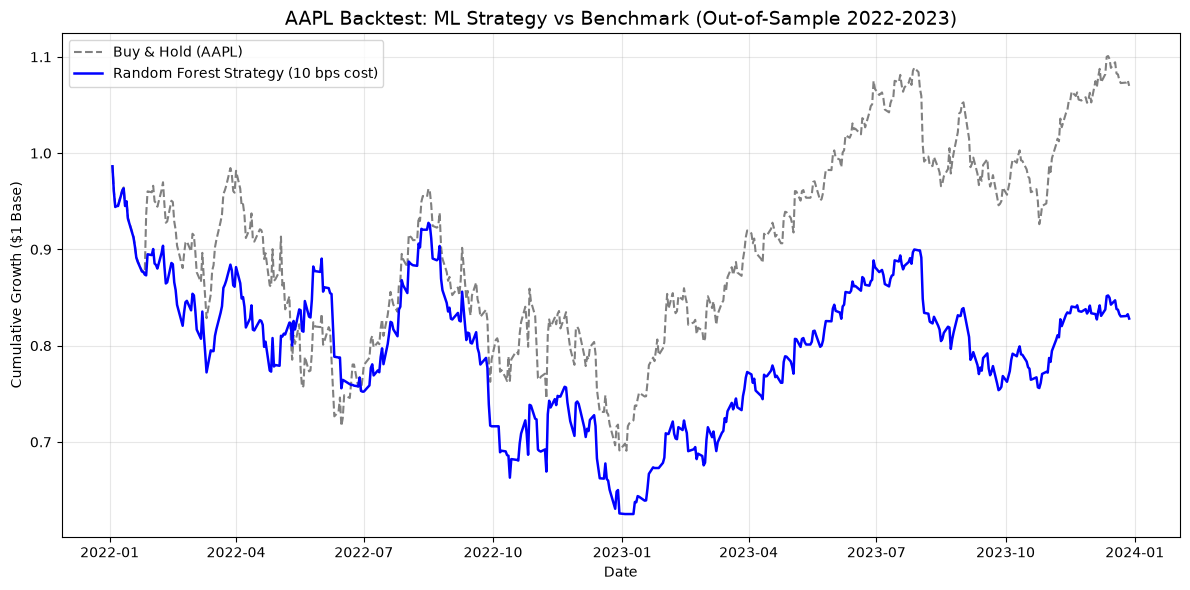

In [6]:
plt.figure(figsize=(12, 6))
plt.plot(backtest_df.index, backtest_df['Cum_Market'], label='Buy & Hold (AAPL)', color='gray', linestyle='--')
plt.plot(backtest_df.index, backtest_df['Cum_Strategy'], label='Random Forest Strategy (10 bps cost)', color='blue', linewidth=1.8)
plt.title(f"{TICKER} Backtest: ML Strategy vs Benchmark (Out-of-Sample 2022-2023)", fontsize=14)
plt.xlabel('Date')
plt.ylabel('Cumulative Growth ($1 Base)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()